# Assignment 2

**name:** Maria Drambyan

**email:** md223sd@student.lnu.se

In this Assignment, you will use Python to handle several exercises related to gradient descent, linear regression, logistic regression, etc.
All exercises are individual. 
We expect you to submit a Jupyter Notebook (i.e., pre-organized and provided through Moodle) and the .py files with the classes’ exercise implementations. 
Your submission should include all the datasets and files we need to run your programs (we will run your notebook). 
When grading your assignments, we will, in addition to functionality, also take into account code quality. 
We expect well-structured and efficient solutions.

In this assignment, you must implement all models as subclasses of MachineLearning-
Model. 
Since the class MachineLearningModel provides the abstract methods fit, predict,
and evaluate, your implementations should provide implementations for such methods.
Please check the documentation of MachineLearningModel to understand what these methods
should do, as well as what their input parameters are and what they should return as results.
You must also implement the classes DecisionBoundary, ROCAnalysis, and ForwardSelection
provided to you. 
Please check their documentation to understand what these methods
should do, what their input parameters are, and what they should return as results. All your
implementations of such classes will be used throughout this assignment.

## Lecture 2 - Linear and Polynomial Regression

### Guidelines for model implementation (Mandatory)

1. Implement a class **RegressionModelNormalEquation** that implements the abstract
class **MachineLearningModel**. All methods should be implemented and properly documented.
This class must work for polynomials of any degree (i.e., an input parameter that
must be captured in the class constructor).

2. Implement a class **RegressionModelGradientDescent** that implements the abstract
class **MachineLearningModel**. All methods should be implemented and properly documented.
This class must work for polynomials of any degree and receive other parameters
such as the learning rate and number of iterations.

3. Both implementations should be vectorized. When implementing these classes, your
vector β should start with all values as 0. In implementing the fit() method, ensure
you track how the cost function evolved over the number of iterations (i.e., store it in an
array you can retrieve after the model is built). This will be needed later in the assignment.

### Validation of your model implementation (1-4 Mandatory, 5-6 Non-mandatory)

1. **(Mandatory)** In this part, you will use a reduced version of the Boston Housing Dataset (housingboston.csv). We will use the first two input variables as the features in this part of the assignment. The last variable is the value to predict.
* **INDUS:** proportion of nonretail business acres per town.
* **RM:** average number of rooms per dwelling.
* **MEDV:** Median value of owner-occupied homes in $1,000s.

Read the dataset and store the values as vectors in the variables $X_e$ and $y$. For this part of the assignment, the degree of the polynomial for your models must be 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("datasets/housing-boston.csv", delimiter=",", skip_header=1)

X = data[:, :2]
y = data[:, 2]

degree = 1

2. **(Mandatory)** Plot the dataset. You must plot two figures side by side (e g., use the subplot method), with the predicted value as the $y-axis$ and each variable on the $x-axis$. 

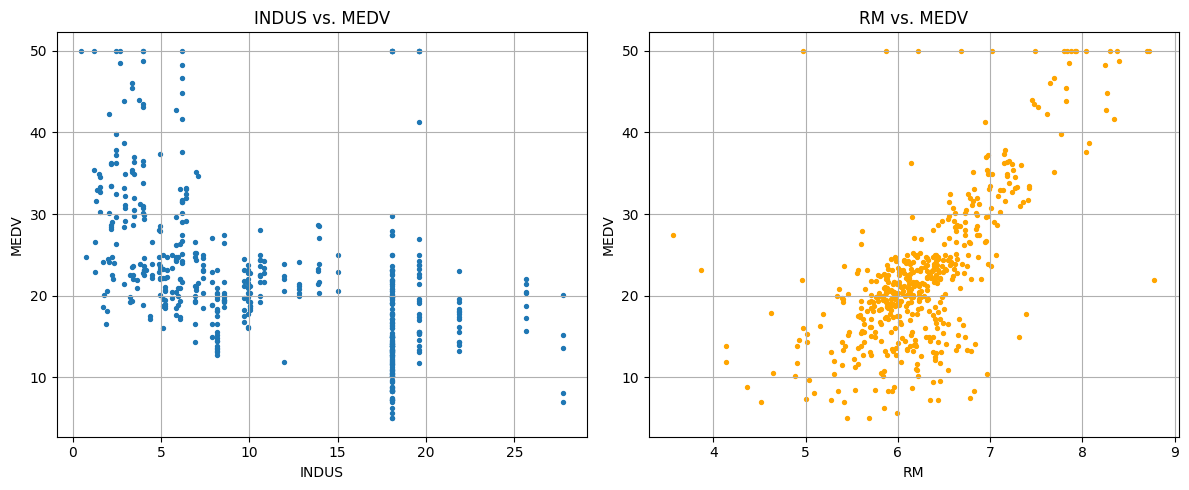

In [2]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y, s=8)
plt.title("INDUS vs. MEDV")
plt.xlabel("INDUS")
plt.ylabel("MEDV")
plt.grid()

plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], y, s=8, color="orange")
plt.title("RM vs. MEDV")
plt.xlabel("RM")
plt.ylabel("MEDV")
plt.grid()

plt.tight_layout()
plt.show()

3. **(Mandatory)** Use your implementation of the regression model with the normal equation (RegressionModelNormalEquation) and report:

* The values for $\beta$. 

* The cost.

* The predicted value for an instance with values for INDUS and TAX equals to $,$, respectively.


In [3]:
import MachineLearningModel as mlm

model_ne = mlm.RegressionModelNormalEquation(degree)

model_ne.fit(X, y)

print("******** NORMAL EQUATION WITHOUT NORMALIZARION ********")
print(f"Beta Values: {model_ne.beta}")
print(f"Cost: {model_ne.cost_history}")

indus_value = 2.31
rm_value = 6.575
prediction = model_ne.predict(np.array([[indus_value, rm_value]]))

print(f"Prediction for INDUS and RM : {prediction[0]}")


******** NORMAL EQUATION WITHOUT NORMALIZARION ********
Beta Values: [-22.89831573  -0.33471389   7.82205511]
Cost: 39.14548321146509
Prediction for INDUS and RM : 27.75850754879836


4. **(Mandatory)** Now, normalize the input features, run the regression model with the normal equation, and report the same items. 
The predicted values for this experiment should be the same, but the $\beta$ values change. Why?

---

Normalization changes the scale of features, altering $\beta$ values but keeping predictions the same. The model adjusts $\beta$ to account for the changes in the data:

- Without normalization: ${y} = \beta_0 + \beta_1x_1 + \beta_2x_2$
- With normalization: ${y} = \beta_0' + \beta_1'\frac{(x_1 - \mu_1)}{\sigma_1} + \beta_2'\frac{(x_2 - \mu_2)}{\sigma_2}$

$\beta$ values change to maintain consistent predictions.



In [4]:
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

model_ne_norm = mlm.RegressionModelNormalEquation(degree)

model_ne_norm.fit(X_norm, y)

print("******** NORMAL EQUATION WITH NORMALIZARION ********")
print(f"Beta Values: {model_ne_norm.beta}")
print(f"Cost: {model_ne_norm.cost_history}")

indus_value_norm = (2.31 - X_mean[0]) / X_std[0]
rm_value_norm = (6.575 - X_mean[1]) / X_std[1]
prediction_norm = model_ne_norm.predict(np.array([[indus_value_norm, rm_value_norm]]))
print(f"Prediction for INDUS and RM : {prediction_norm[0]}")

******** NORMAL EQUATION WITH NORMALIZARION ********
Beta Values: [22.53280632 -2.29398525  5.49047659]
Cost: 39.1454832114651
Prediction for INDUS and RM : 27.758507548798473


5. **(Non-Mandatory)** Now, you will work with your implementation of the gradient descent for any degree polynomial. In this part, you must compare how the cost function evolves by using your model using a non-normalized and a normalized instance of your RegressionModelGradientDescen class. 
    * You must plot two figures (e.g., use subplots) side by side to show how the cost evolves over 3000 iterations with a learning rate of $0.001$ using and not using feature normalization. 
    * Describe what is happening and why this happens (i.e., using or not normalization).        
    
---

Without normalization the cost drops really fast at the start but then flattens out quickly. On the other hand, with normalization the cost decreases more steadily and smoothly. This happens because normalization makes sure all features are on a similar scale, so the optimization process is more balanced, without it features with bigger scales take over, causing the algorithm to make huge steps at first but then struggle to improve much after that. That’s why we see a sharp drop early on, followed by barely any progress.

Normalization helps the algorithm converge more efficiently and consistently by keeping any single feature from having too much influence.

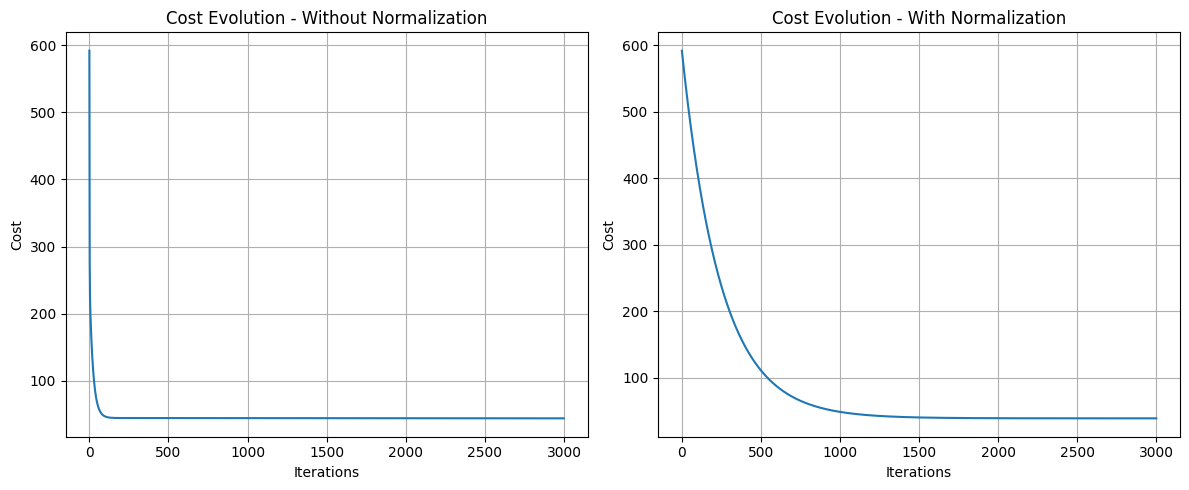

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("datasets/housing-boston.csv", delimiter=",", skip_header=1)

X = data[:, :2]
y = data[:, 2]

degree = 1

model_gd = mlm.RegressionModelGradientDescent(degree, learning_rate=0.001, num_iterations=3000)
model_gd.fit(X, y)

model_gd_norm = mlm.RegressionModelGradientDescent(degree, learning_rate=0.001, num_iterations=3000)

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

model_gd_norm.fit(X_norm, y)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(model_gd.cost_history)
plt.title('Cost Evolution - Without Normalization')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(model_gd_norm.cost_history)
plt.title('Cost Evolution - With Normalization')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.grid()

plt.tight_layout()
plt.show()

6. **(Non-Mandatory)** Finally, find and plot a figure with the hyperparameter's learning rate and the number of iterations (using the normalized version) such that you get within a difference of 1\% of the final cost for the normal equation using this dataset.

---

Looking at the plot, higher learning rates get to the optimal solution way faster. For example, the smallest learning rate (0.001) takes 1817 iterations to get within 1% of the target cost, while the largest one (0.1) only needs 17 iterations.

It’s kind of an inverse relationship, each 5x increase in learning rate reduces the required iterations by approximately 5x. This shows that with gradient descent higher learning rates are faster but can overshoot or diverge, while lower ones are slower but more stable.

For this normalized dataset, a learning rate of 0.1 seems to work best. It’s the fastest to converge while still hitting the target cost. All the learning rates eventually get close to the reference cost of 39.145483, which shows that normalization helps keep things stable no matter the learning rate.

LR=0.001: Converged within 1% after 1817 iterations
LR=0.005: Converged within 1% after 362 iterations
LR=0.01: Converged within 1% after 181 iterations
LR=0.05: Converged within 1% after 35 iterations
LR=0.1: Converged within 1% after 17 iterations


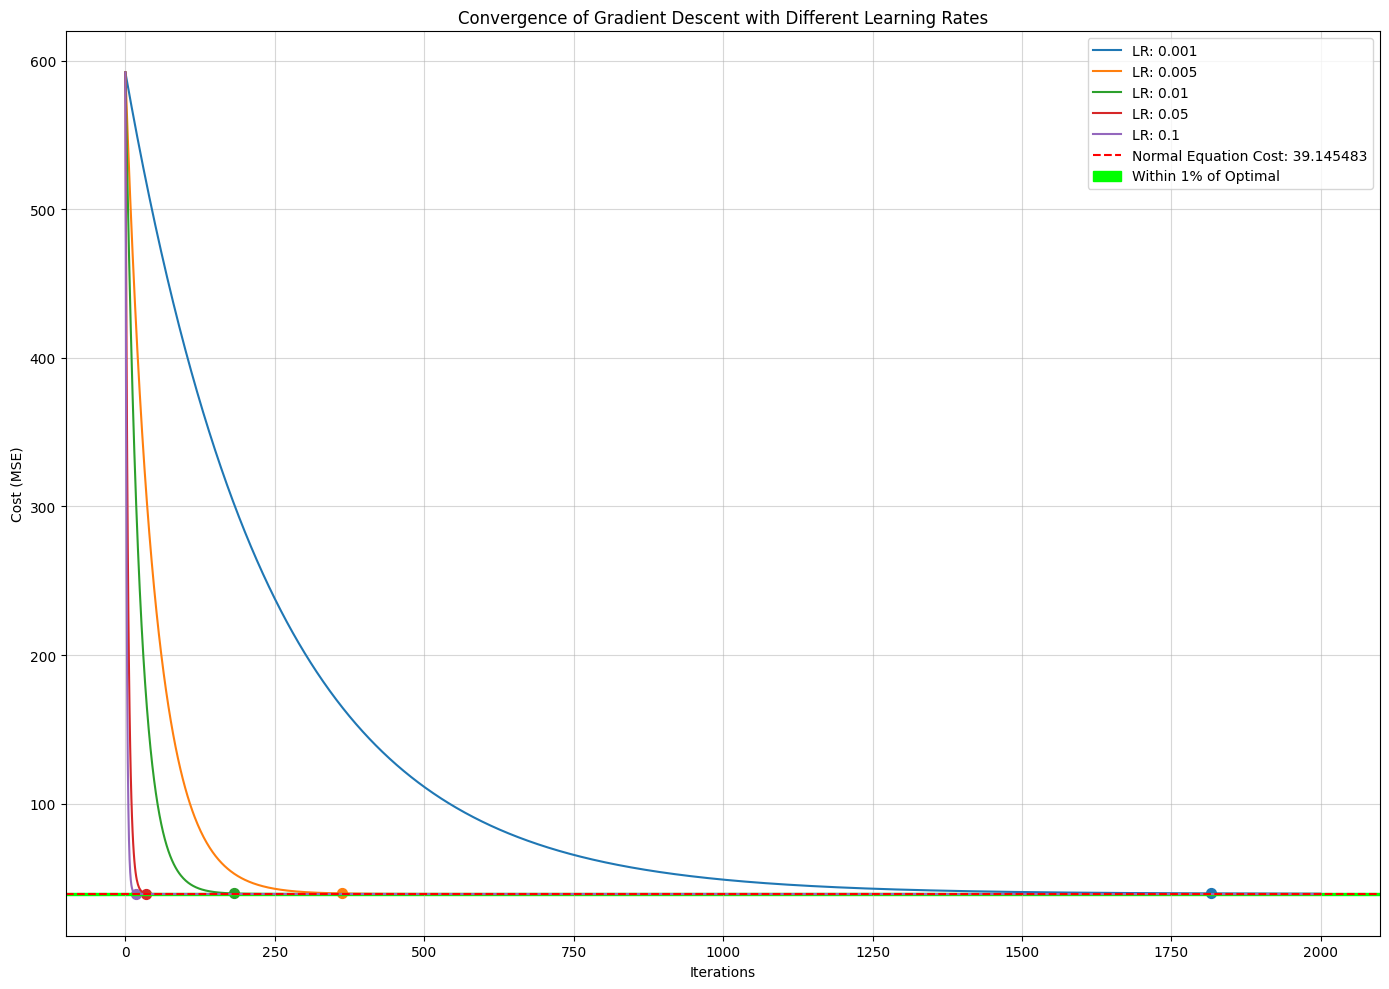

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("datasets/housing-boston.csv", delimiter=",", skip_header=1)

X = data[:, :2]
y = data[:, 2]

degree = 1

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

model_norm = mlm.RegressionModelNormalEquation(degree)
model_norm.fit(X_norm, y)
reference_cost = model_norm.cost_history

learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]
max_iterations = 2000

plt.figure(figsize=(14, 10))

convergence_data = []

for lr in learning_rates:
    model = mlm.RegressionModelGradientDescent(degree, learning_rate=lr, num_iterations=max_iterations)
    model.fit(X_norm, y)
    
    plt.plot(model.cost_history, label=f'LR: {lr}')
    
    costs_array = np.array(model.cost_history)
    threshold_indices = np.where(abs(costs_array - reference_cost) / reference_cost <= 0.01)[0]
    
    if len(threshold_indices) > 0:
        first_convergence = threshold_indices[0]
        plt.scatter(first_convergence, model.cost_history[first_convergence], marker='o', s=50)
        
        convergence_data.append({
            'learning_rate': lr,
            'iterations': first_convergence,
            'cost': model.cost_history[first_convergence]
        })
        
        print(f"LR={lr}: Converged within 1% after {first_convergence} iterations")
    else:
        print(f"LR={lr}: Did not converge within 1% during {max_iterations} iterations")

plt.axhline(y=reference_cost, color='r', linestyle='--', label=f'Normal Equation Cost: {reference_cost:.6f}')
plt.axhspan(reference_cost * 0.99, reference_cost * 1.01, color='lime', label='Within 1% of Optimal')

plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.title('Convergence of Gradient Descent with Different Learning Rates')
plt.legend()
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

## Lecture 2 - Testing your Multivariate Regression Model (1-2 Mandatory, 3 Non-mandatory)

In this exercise, we will use the file secret_polynomial.csv. The data consists of 400 x, y points generated from a polynomial with some Gaussian noise added.

1. **(Mandatory)** Start by creating a procedure to split the dataset into training and test sets. The proportion must be 80% for training and 20% for testing. Show your procedure working by plotting a figure with 3 subplots. The first plot must be the dataset with all data. The second must be the training set and the third the test set. 


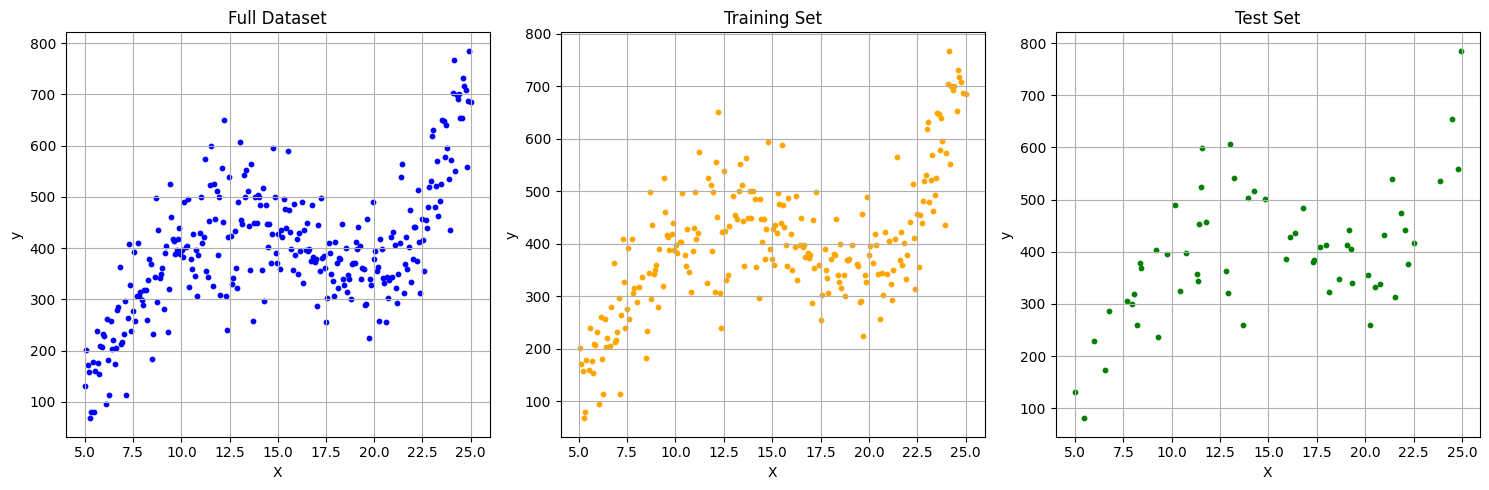

In [7]:
import numpy as np
import matplotlib.pyplot as plt 
import MachineLearningModel as mlm

data = np.genfromtxt("datasets/secret_polynomial.csv", delimiter=",", skip_header=1)
X = data[:, 0]
y = data[:, 1]

np.random.seed(65)
indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))
train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
y_train = y[train_indices]
X_test = X[test_indices]
y_test = y[test_indices]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(X, y, s=10, color="blue")
plt.title("Full Dataset")
plt.xlabel("X")
plt.ylabel("y")
plt.grid()

plt.subplot(1, 3, 2)
plt.scatter(X_train, y_train, s=10, color="orange")
plt.title("Training Set")
plt.xlabel("X")
plt.ylabel("y")
plt.grid()

plt.subplot(1, 3, 3)
plt.scatter(X_test, y_test, s=10, color="green")
plt.title("Test Set")
plt.xlabel("X")
plt.ylabel("y")
plt.grid()

plt.tight_layout()
plt.show()

2. **(Mandatory)** Now fit and plot (e.g., using subplots) all polynomial models for degrees $d\in [1,6]$. Observe your figure and decide which degree gives the best fit. Motivate your answer.

---

From the plots, we can see that degrees 4 and 5 seem to fit the data best.

Degrees 1 and 2 clearly underfix, they miss the key patterns, and the straight line (degree 1) doesn’t even come close to the curves. Degree 3 does better, picking up the rise at the ends and the dip in the middle, but it’s still not quite there.

Degrees 4 and 5 fit the data well, they capture the rise and lows of dats. Degree 6 doesn’t really show any improvements to degree 5, so it might start overfitting at that point.

I think degree 4 is the best, it gets all the important patterns without adding extra complexity.

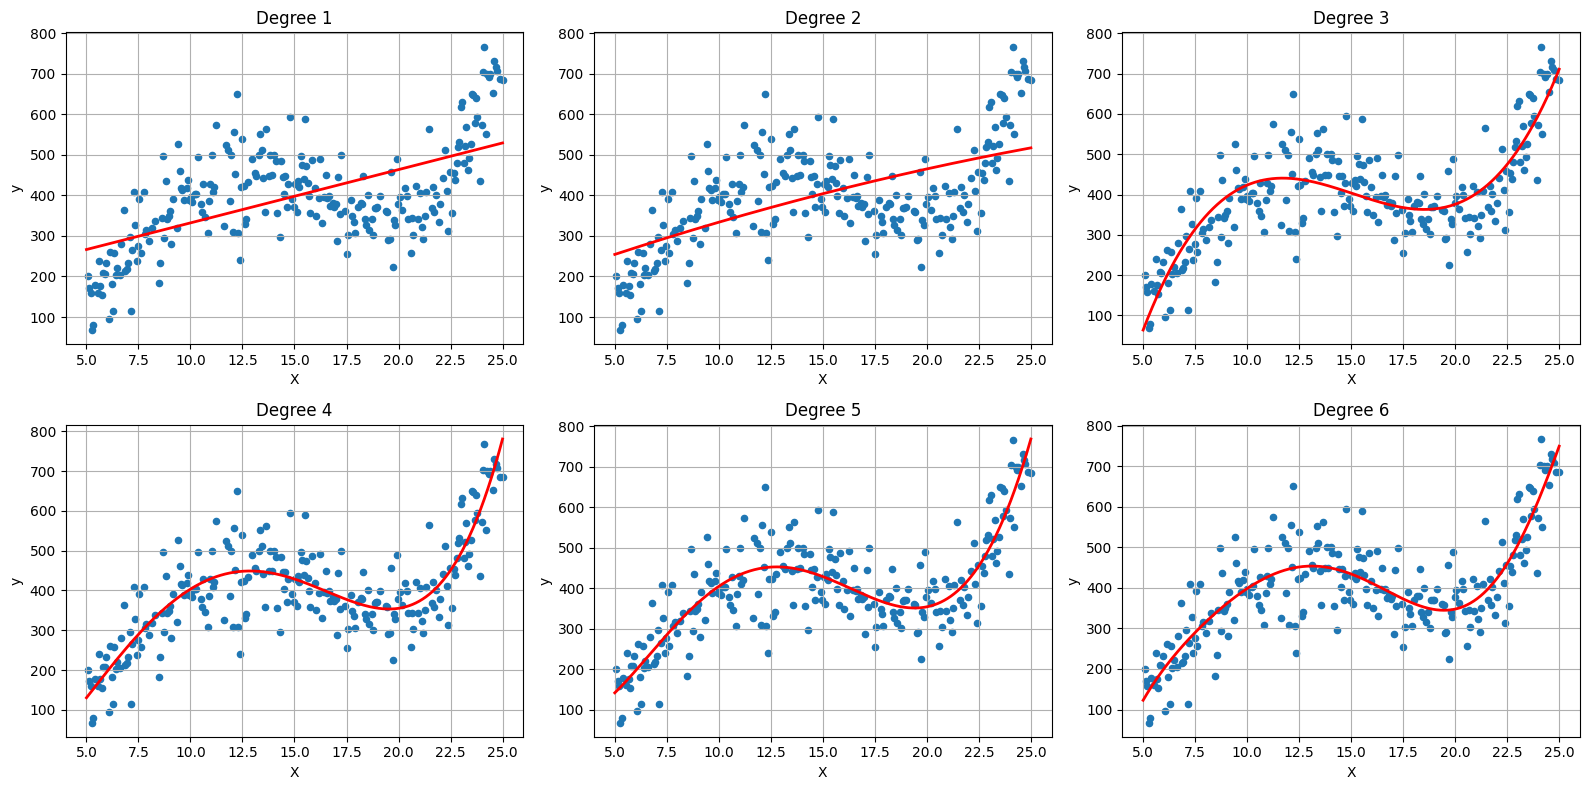

In [8]:
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_train_norm = (X_train - X_mean) / X_std
X_norm = (X - X_mean) / X_std

degrees = range(1, 7)

plt.figure(figsize=(16, 8))

x_curve = np.linspace(min(X), max(X), 1000).reshape(-1, 1)

x_curve_norm = (x_curve - X_mean) / X_std

for i, degree in enumerate(degrees):
    model = mlm.RegressionModelNormalEquation(degree)
    model.fit(X_train_norm, y_train)
    
    plt.subplot(2, 3, i + 1)
    plt.scatter(X_train, y_train, s=20)
    plt.plot(x_curve, model.predict(x_curve_norm), color="red", linewidth=2)
    plt.title(f"Degree {degree}")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.grid()
    
plt.tight_layout()
plt.show()

3. **(Non-Mandatory)** To increase the confidence of your answer, you must divide the data into training and test sets and make repeated runs with shuffled data (at least 20 runs). You must decide on the best way to make this decision. By using this approach, what is your decision and why? 

---

Based on the box plot of test errors across multiple runs with shuffled data, degree 4 provides the optimal polynomial fit.

Looking at the MSE distributions:

- Degrees 1-2 have much higher errors (~11,000) with wide variation
- At degree 3 there is a big improvement (MSE ~5,500)
- Degree 4 has the lowest median MSE (~5,300)
- Degrees 5-6 show no meaningful improvement over degree 4

Degrees 3-6 all do much better than the lower degrees, but degree 4 seems to be the best since it has the lowest test error. Degrees 5 and 6 might overfit the data and don’t really improve predictions, they actually perform about the same or even a bit worse.

Overall, degree 4 is the best balance between keeping the model simple and making accurate predictions.

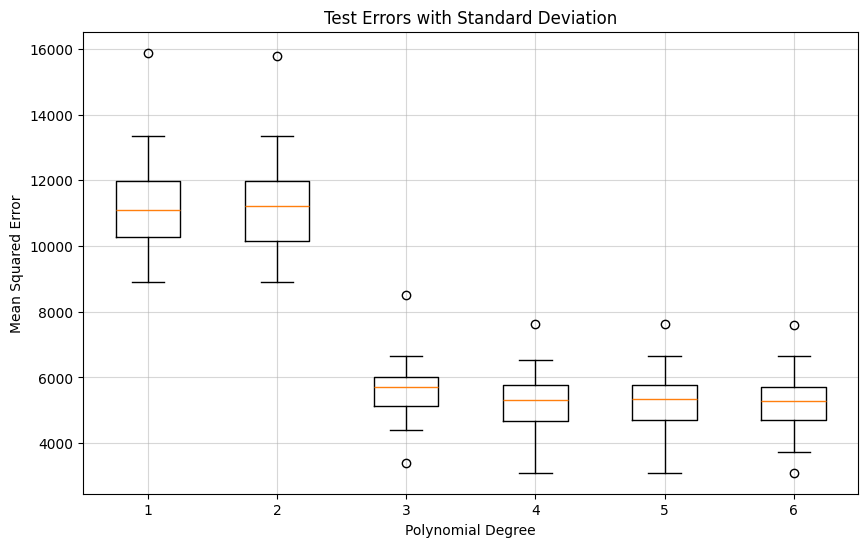

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

seed = 65
runs_num = 20
degrees = range(1, 7)

data = np.genfromtxt("datasets/secret_polynomial.csv", delimiter=",", skip_header=1)
X = data[:, 0].reshape(-1, 1)
y = data[:, 1]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

X_curve = np.linspace(min(X)[0], max(X)[0], 1000).reshape(-1, 1)
x_curve_norm = (X_curve - X_mean) / X_std

all_test_errors = np.zeros((runs_num, len(degrees)))

for run in range(runs_num):
    np.random.seed(seed + run)
    
    indices = np.random.permutation(len(X_norm))
    X_norm = X_norm[indices]
    y = y[indices]
    
    X_train = X_norm[: int(len(X_norm) * 0.8)]
    y_train = y[: int(len(y) * 0.8)]
    
    X_test = X_norm[int(len(X_norm) * 0.8) :]
    y_test = y[int(len(y) * 0.8) :]
    
    for i, degree in enumerate(degrees):
        model = mlm.RegressionModelNormalEquation(degree)
        model.fit(X_train, y_train)
        
        test_mse = model.evaluate(X_test, y_test)
        all_test_errors[run, i] = test_mse
        
mean_test_errors = np.mean(all_test_errors, axis=0)
std_test_errors = np.std(all_test_errors, axis=0)

plt.figure(figsize=(10, 6))
plt.boxplot(all_test_errors, positions=degrees)
plt.title("Test Errors with Standard Deviation")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.xticks(degrees)
plt.grid(alpha=0.5)
plt.show()


## Lecture 3 - Logistic Regression

### Guidelines for model implementation (Mandatory)

1. Implement a class LogisticRegressionModel that implements the abstract class MachineLearningModel.
All methods should be implemented and properly documented.
This class receives parameters such as the learning rate and number of iterations. This
class should be implemented in a way that works for two classes only (i.e., 0 or 1).

2. Implement a class NonLinearLogisticRegressionModel that implements the abstract
class MachineLearningModel. All methods should be implemented and properly documented.
This class must work for polynomials of any degree and receive other parameters
such as the learning rate and number of iterations. This class should work for only two
input variables (e.g., X1 and X2, as discussed in class). This class should be implemented
in a way that works for two classes only (i.e., 0 or 1).

3. Both implementations should be vectorized. When implementing these classes, your vector
β should start with all values as 0. In your implementation of the evaluate function, ensure
you keep track of how the cost function evolved over the number of iterations. This will
be needed later in the assignment.

4. Remember that log(0) = undefined. Therefore, you may add a term epsilon = 1e-15 to
prevent this in using the np.log() function. Simply add this term inside the function, and
you will avoid such errors.

### Using your Implementations for the LogisticRegressionModel and the NonLinearLogisticRegressionModel (1-3 Mandatory, 4-6 Non-mandatory)

You will now try to classify bank notes as fake (0) or not (1). This dataset banknote_authentication.csv contains 1372 observations and has 2 features and (in column 3) binary labels of either fake (0) or not (1). Feature data were extracted using a Wavelet Transform tool from images of both fake and non-fake banknotes.

1. **(Mandatory)** Read and normalize the data. Plot the 2 variables in the x and y-axis. Use different colors to plot the classes (i.e., 0 or 1). You should plot two series to obtain this figure.  

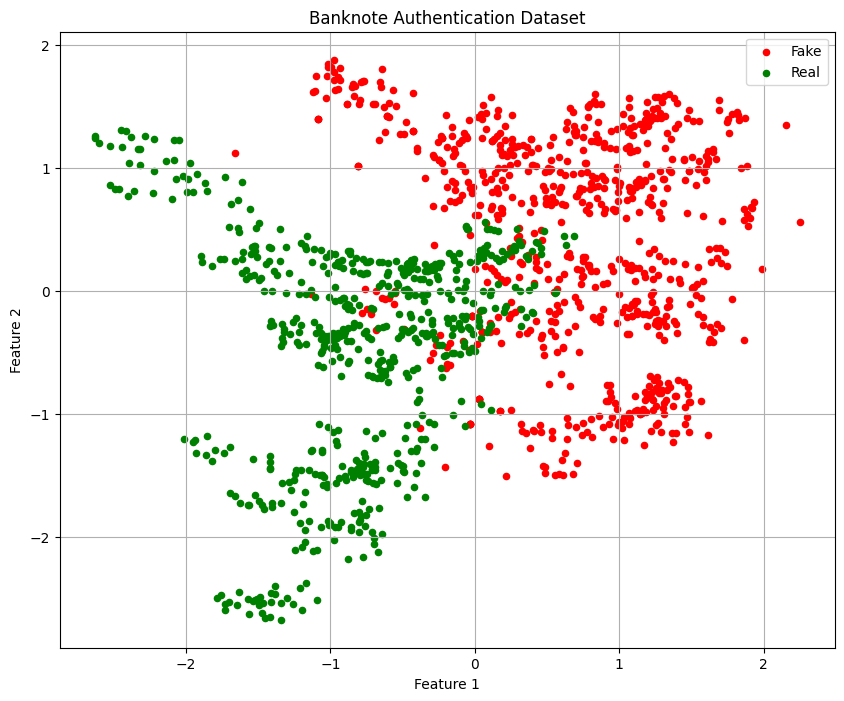

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("datasets/banknote_authentication.csv", delimiter=",")
X = data[:, :2]
y = data[:, 2]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

fake = X_norm[y == 0]
real = X_norm[y == 1]

plt.figure(figsize=(10, 8))
plt.scatter(fake[:, 0], fake[:, 1], s=20, color="red", label="Fake")
plt.scatter(real[:, 0], real[:, 1], s=20, color="green", label="Real")
plt.title("Banknote Authentication Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid()
plt.show()

2. **(Mandatory)** Separate a validation set with 20\% of the data. We will call the remaining 80\% a sub-dataset.

In [11]:
np.random.seed(65)
indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))
train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X_norm[train_indices]
y_train = y[train_indices]
X_test = X_norm[test_indices]
y_test = y[test_indices]

3. **(Mandatory)** Your task now is to decide on a learning rate and the number of iterations that would work well for your implementations of the LogisticRegression and your NonLinearLogisticRegression. The degree for the NonLinearLogisticRegression model must be 2. Create a figure for each model showing the learning rate and number of iterations and plot the cost function $J(\beta)$ as a function over iterations. This approach must use the sub-dataset (the 80\%) from step 2. Discuss your choice for an appropriate learning rate and the number of iterations.

---

Here are my results, based on the plots:

Linear Logistic Regression:

- Learning rate: 0.07
- Iterations: 1000

For the linear model, a learning rate of 0.07 works well. It drops the cost quickly at first and avoids the slow progress seen with lower rates (like 0.001 or 0.01). By 1000 iterations, the cost levels off around 0.28, with only small improvements after that.

Nonlinear Logistic Regression:

- Learning rate: 0.07
- Iterations: 2000
For the nonlinear model, 0.07 also performs great. At 1000 iterations, the cost is about 0.21, and by 2000 iterations, it fully converges to around 0.20. Going beyond 2000 iterations doesn’t really help.

The nonlinear model’s lower final cost (0.20 vs. 0.28) shows it fits the data better than the linear model, making the added complexity of a degree 2 polynomial worth it.

In [12]:
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.07, 0.1]
num_iterations = 1000
iterations_range = [100, 200, 500, 1000, 2000, 5000]

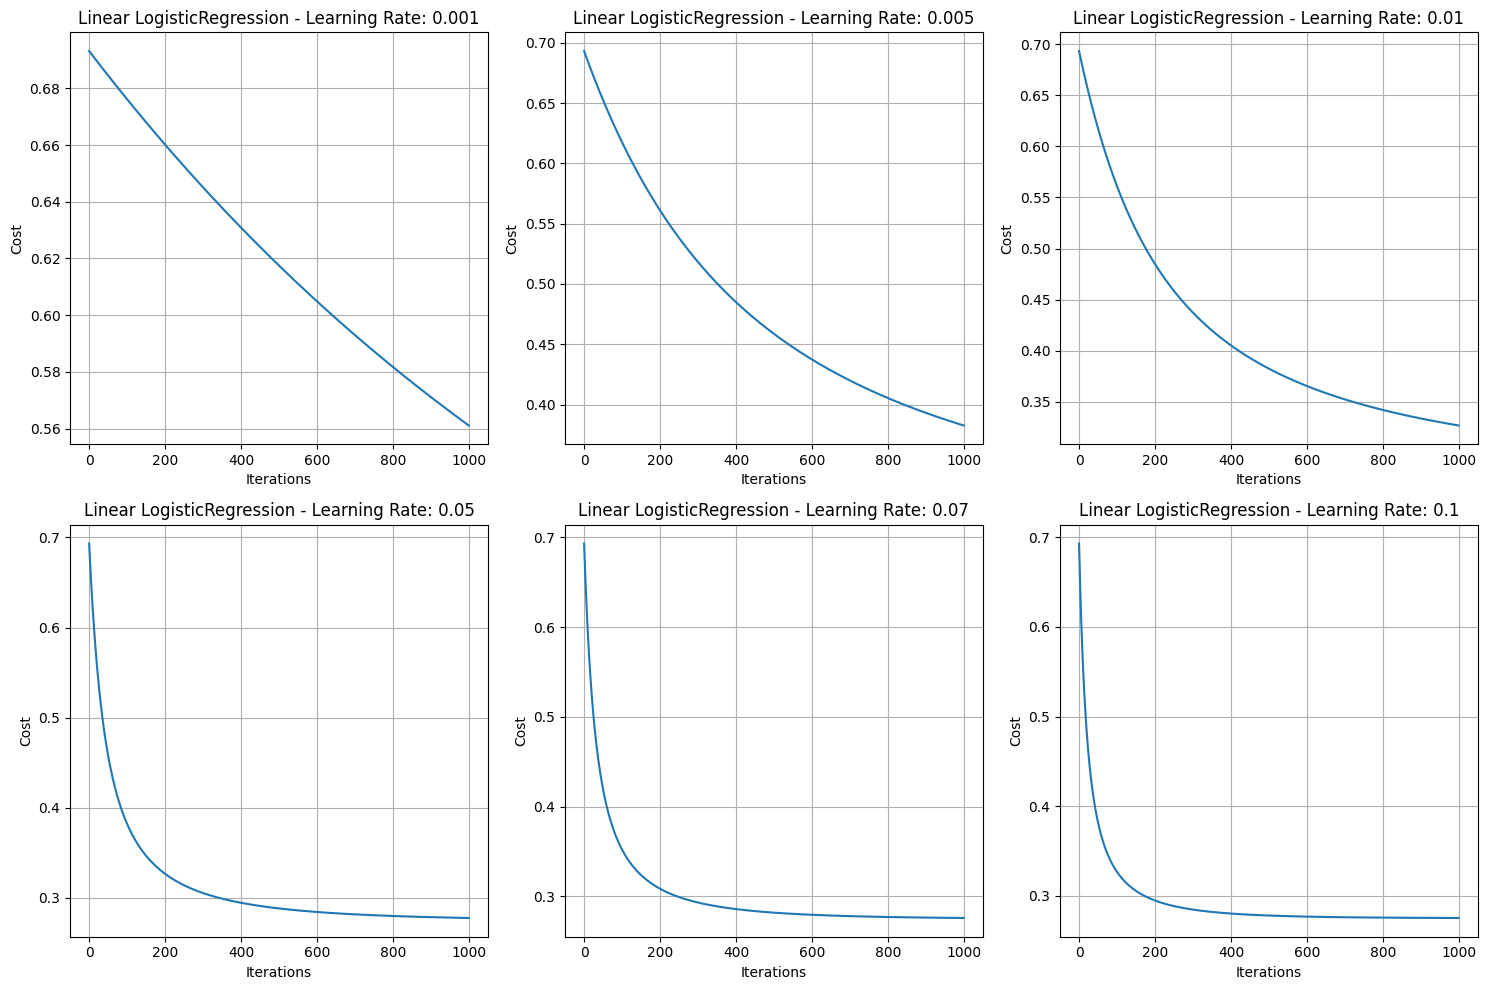

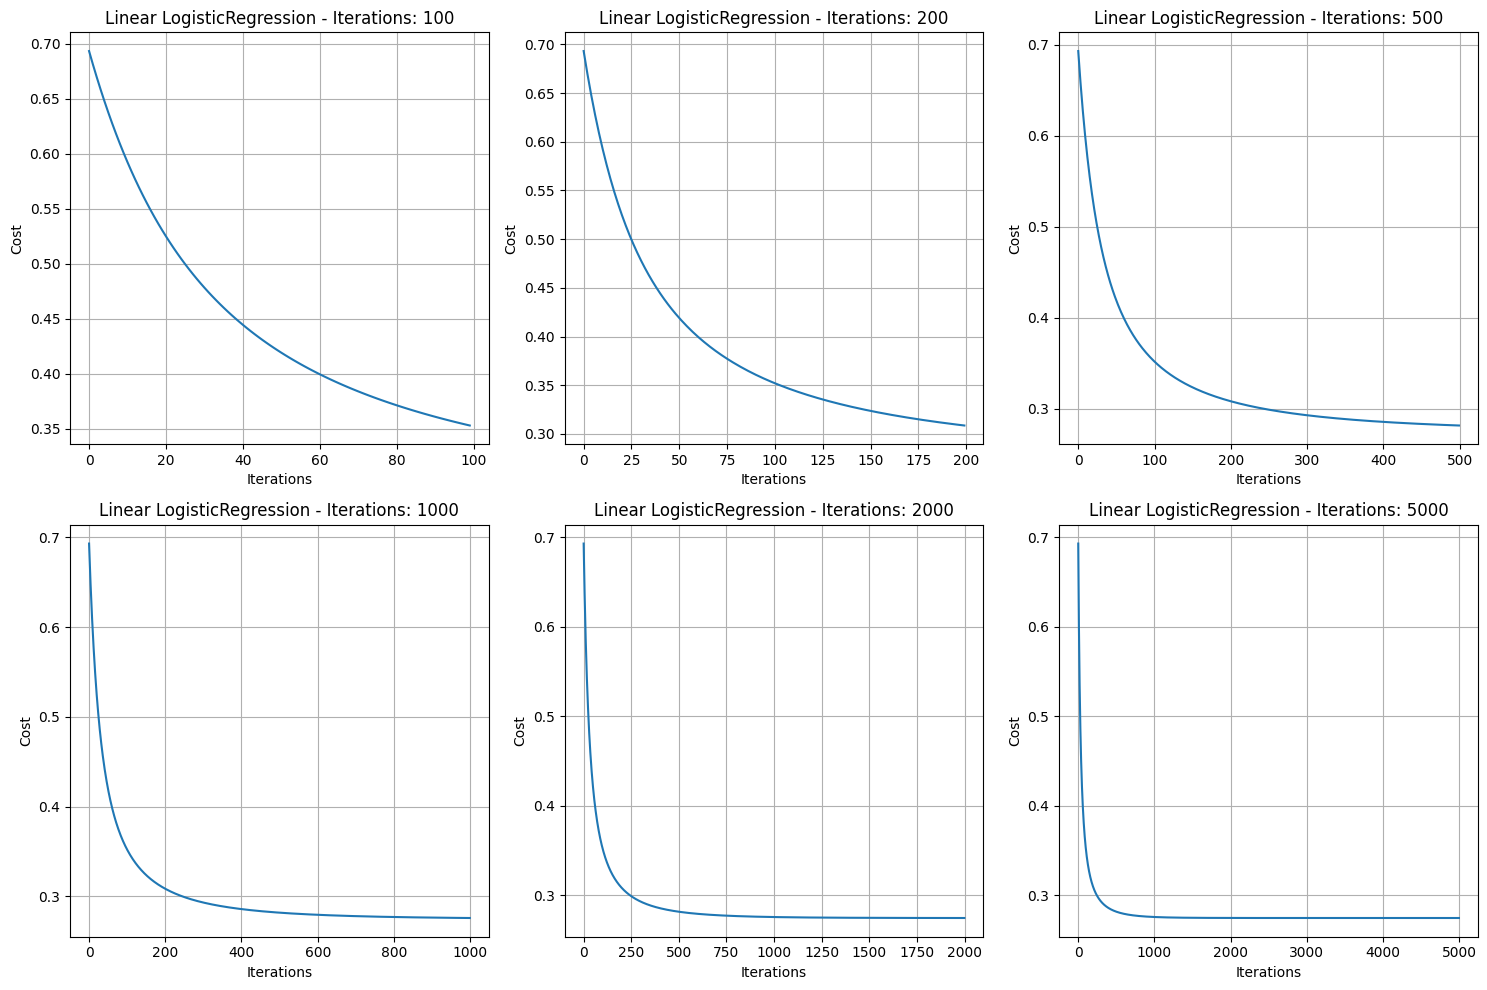

Linear model final cost with lr=0.07, iterations=1000: 0.275880


In [13]:
plt.figure(figsize=(15, 10))

for i, lr in enumerate(learning_rates):
    model = mlm.LogisticRegression(learning_rate=lr, num_iterations=num_iterations)
    model.fit(X_train, y_train)
    
    plt.subplot(2, 3, i+1)
    plt.plot(range(num_iterations), model.cost_history)
    plt.title(f'Linear LogisticRegression - Learning Rate: {lr}')
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.grid()

plt.tight_layout()
plt.show()


best_lr_lin = 0.07

plt.figure(figsize=(15, 10))
for i, iters in enumerate(iterations_range):
    model = mlm.LogisticRegression(learning_rate=best_lr_lin, num_iterations=iters)
    model.fit(X_train, y_train)
    
    plt.subplot(2, 3, i+1)
    plt.plot(range(iters), model.cost_history)
    plt.title(f'Linear LogisticRegression - Iterations: {iters}')
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.grid()

plt.tight_layout()
plt.show()

best_iter_lin = 1000

linear_model = mlm.LogisticRegression(learning_rate=best_lr_lin, num_iterations=best_iter_lin)
linear_model.fit(X_train, y_train)
linear_final_cost = linear_model.cost_history[-1]

print(f"Linear model final cost with lr={best_lr_lin}, iterations={best_iter_lin}: {linear_final_cost:.6f}")


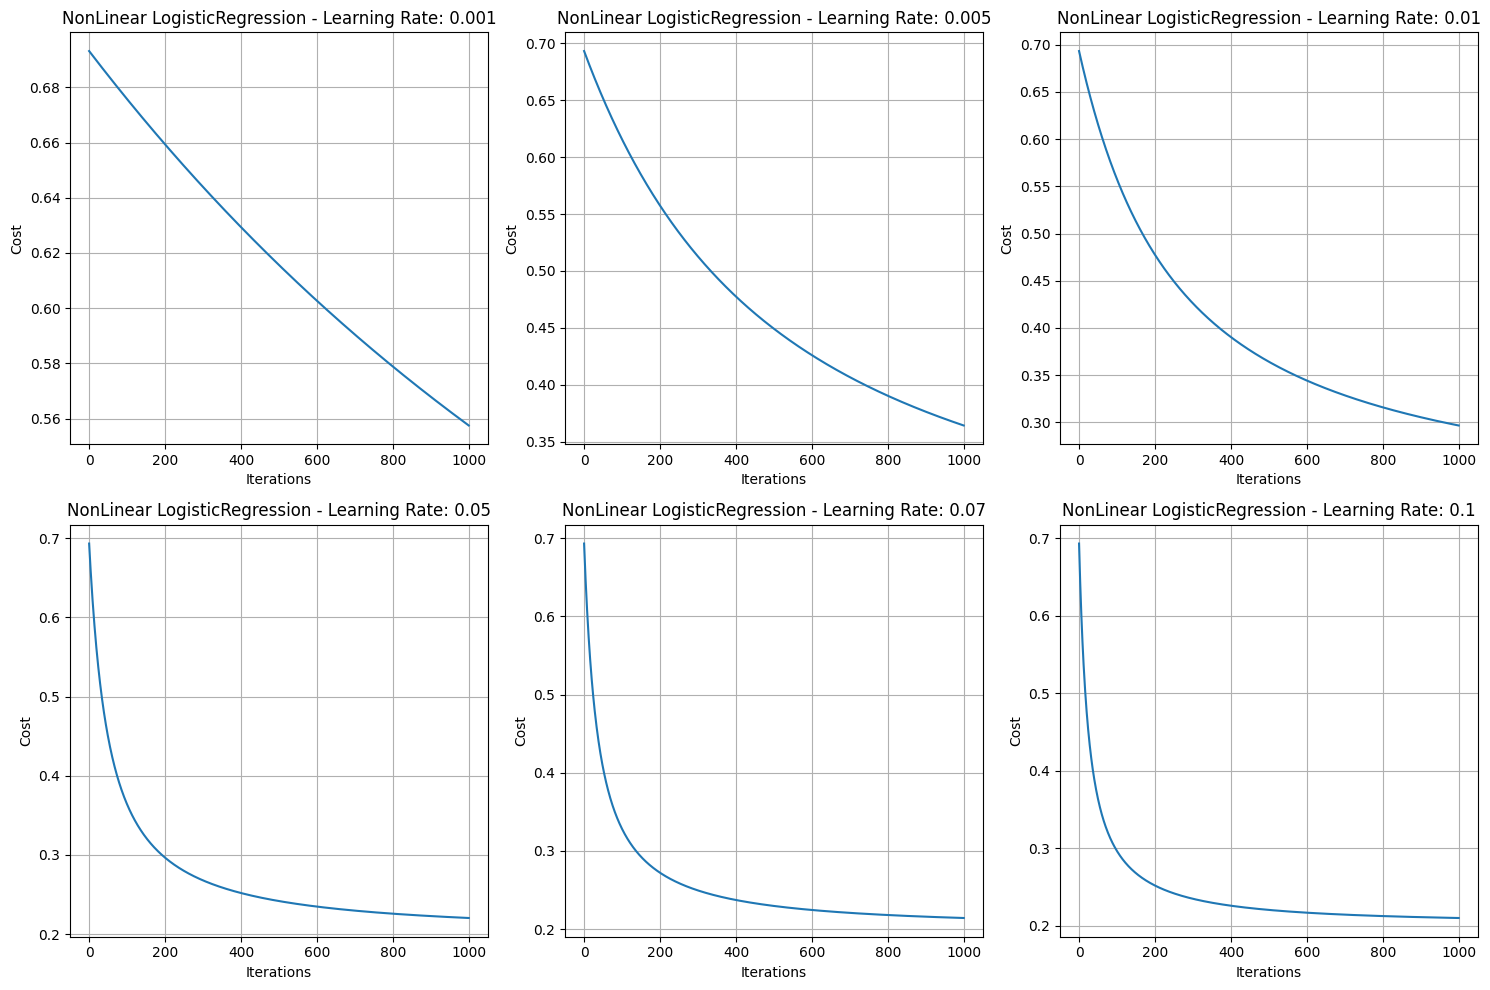

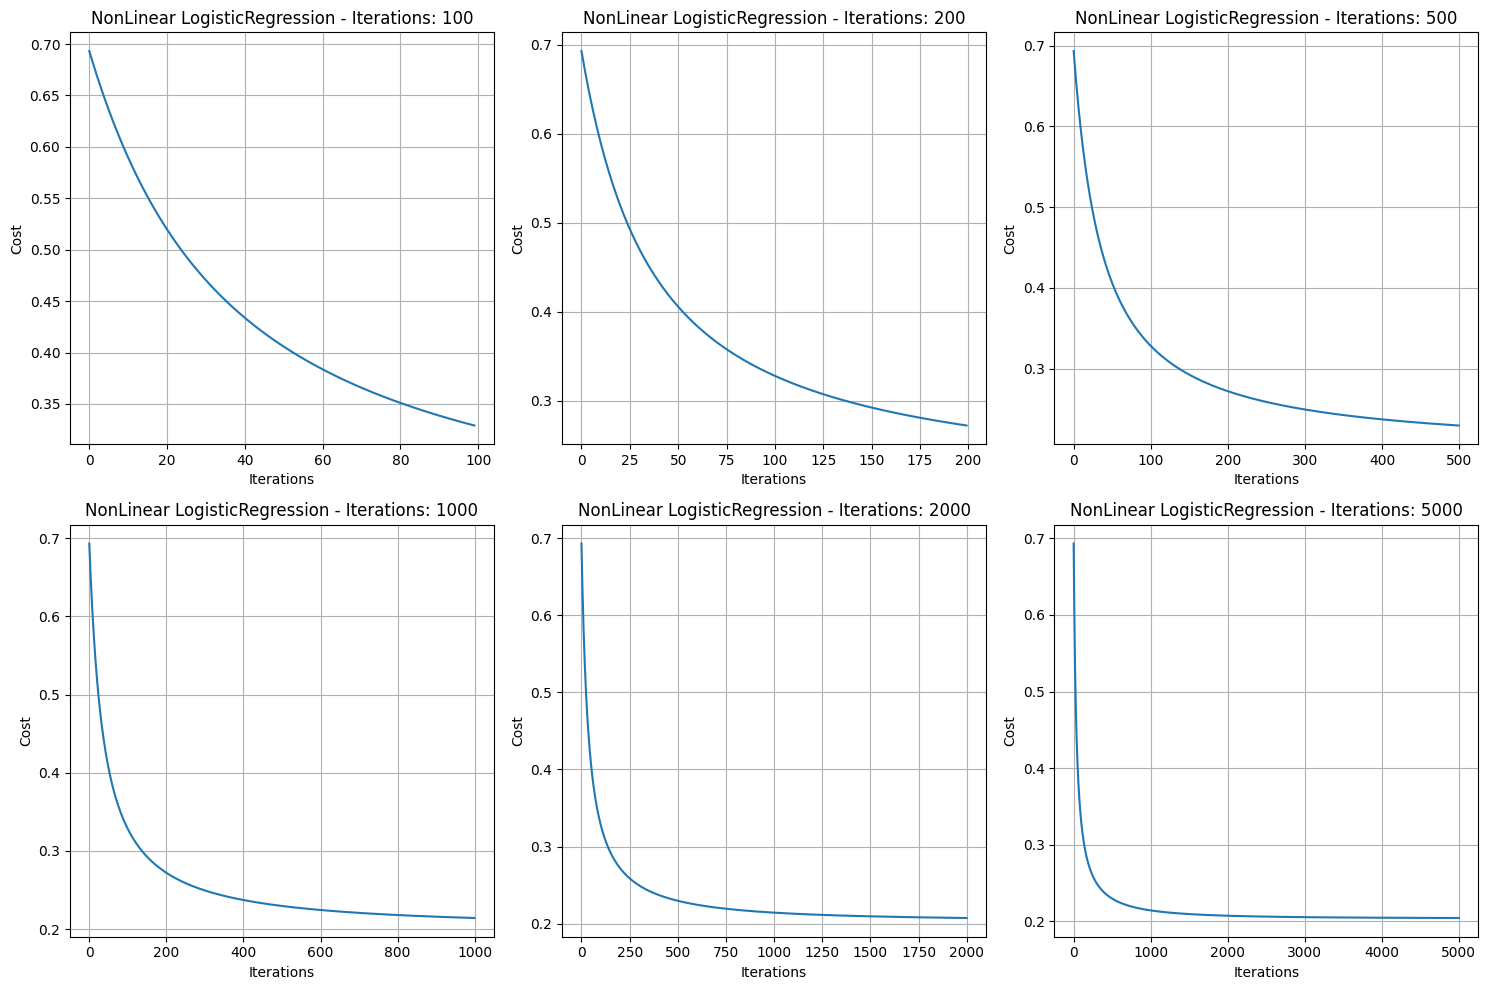

Nonlinear model final cost with lr=0.07, iterations=2000: 0.207299


In [14]:
plt.figure(figsize=(15, 10))
for i, lr in enumerate(learning_rates):
    model = mlm.NonLinearLogisticRegression(degree=2, learning_rate=lr, num_iterations=num_iterations)
    model.fit(X_train, y_train)

    plt.subplot(2, 3, i+1)
    plt.plot(range(num_iterations), model.cost_history)
    plt.title(f'NonLinear LogisticRegression - Learning Rate: {lr}')
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.grid(True)

plt.tight_layout()
plt.show()

best_lr_nonlin = 0.07

plt.figure(figsize=(15, 10))
for i, iters in enumerate(iterations_range):
    model = mlm.NonLinearLogisticRegression(degree=2, learning_rate=best_lr_nonlin, num_iterations=iters)
    model.fit(X_train, y_train)
    
    plt.subplot(2, 3, i+1)
    plt.plot(range(iters), model.cost_history)
    plt.title(f'NonLinear LogisticRegression - Iterations: {iters}')
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.grid()

plt.tight_layout()
plt.show()

best_iters = 2000

linear_model = mlm.LogisticRegression(learning_rate=best_lr_nonlin, num_iterations=best_iters)
linear_model.fit(X_train, y_train)
linear_final_cost = linear_model.cost_history[-1]

nonlinear_model = mlm.NonLinearLogisticRegression(degree=2, learning_rate=best_lr_nonlin, num_iterations=best_iters)
nonlinear_model.fit(X_train, y_train)
nonlinear_final_cost = nonlinear_model.cost_history[-1]

print(f"Nonlinear model final cost with lr={best_lr_nonlin}, iterations={best_iters}: {nonlinear_final_cost:.6f}")

5. **(Non-Mandatory)** Repeat 20 times your experiments (i.e., using different seeds) with the decided learning rate and the number of iterations (step 2) using 20 different sub-datasets generated by your method from step 4. Report as a box-plot all accuracies (i.e., percentage of correct classifications) reported by each model in these 20 runs. Compare and discuss the two models. Are they qualitatively the same? Why?

---

From the box plot, the NonLinear model (degree 2) does better than the Linear model across 20 random data splits:

- NonLinear model: Mean accuracy = 91.16% (std: 0.0128)
- Linear model: Mean accuracy = 88.56% (std: 0.0133)

The two models aren’t the same. The nonlinear model’s interquartile range is completely above the linear model’s median, showing a clear improvement. The accuracy boost shows that the data has nonlinear patterns that the degree 2 polynomial can capture.

Both models have similar variance across splits, meaning they’re consistent no matter how the data is split. The nonlinear model’s higher max accuracy (almost 95%) also proves it’s better at fitting the data.

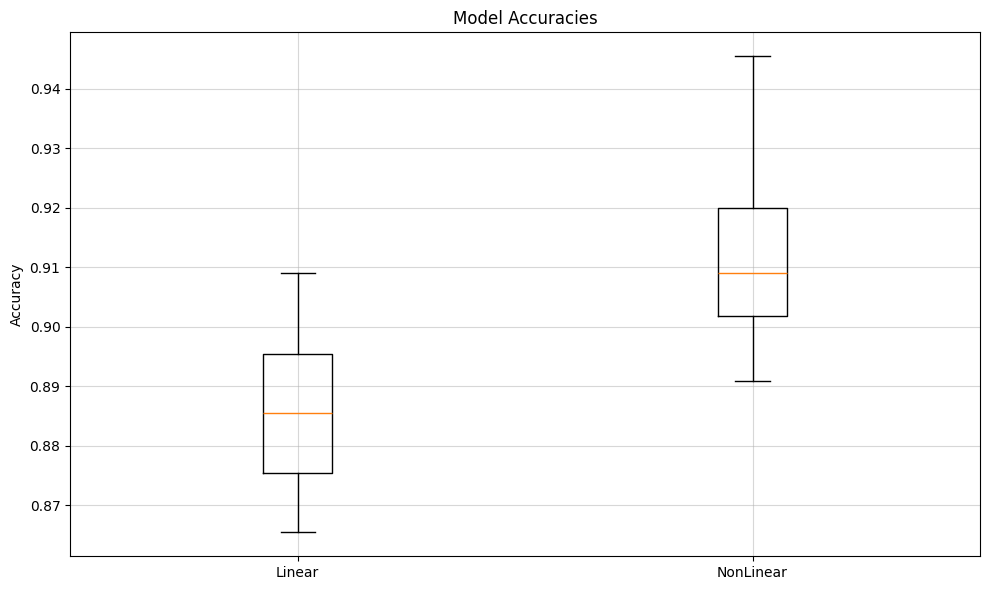


Linear LogisticRegression - Mean accuracy: 0.8856, Std: 0.0133
NonLinear LogisticRegression - Mean accuracy: 0.9116, Std: 0.0128


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm


data = np.genfromtxt("datasets/banknote_authentication.csv", delimiter=",")
X = data[:, :2]
y = data[:, 2]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

num_runs = 20
linear_accuracies = np.zeros(num_runs)
nonlinear_accuracies = np.zeros(num_runs)

best_lr_lin = 0.07
best_lr_nonlin = 0.07
best_iters_lin =  1000
best_iters_nonlin = 2000

degree = 2

seed = 65

for run in range(num_runs): 
    np.random.seed(seed + run)
    indices = np.random.permutation(len(X_norm))
    X_norm_shuffled = X_norm[indices]
    y_shuffles = y[indices]
    
    X_train = X_norm_shuffled[: int(len(X_norm) * 0.8)]
    y_train = y_shuffles[: int(len(y) * 0.8)]
    X_test = X_norm_shuffled[int(len(X_norm) * 0.8) :]
    y_test = y_shuffles[int(len(y) * 0.8) :]
    
    linear_model = mlm.LogisticRegression(learning_rate=best_lr_lin, num_iterations=best_iters_lin)
    linear_model.fit(X_train, y_train)
    linear_predictions = linear_model.predict(X_test)
    linear_accuracy = np.mean(linear_predictions == y_test)
    linear_accuracies[run] = linear_accuracy
    
    nonlinear_model = mlm.NonLinearLogisticRegression(degree=degree, learning_rate=best_lr_nonlin, num_iterations=best_iters_nonlin)
    nonlinear_model.fit(X_train, y_train)
    nonlinear_predictions = nonlinear_model.predict(X_test)
    nonlinear_accuracy = np.mean(nonlinear_predictions == y_test)
    nonlinear_accuracies[run] = nonlinear_accuracy
    
plt.figure(figsize=(10, 6))
plt.boxplot([linear_accuracies, nonlinear_accuracies], tick_labels=["Linear", "NonLinear"])
plt.title("Model Accuracies")
plt.ylabel("Accuracy")
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()
    
linear_mean = np.mean(linear_accuracies)
nonlinear_mean = np.mean(nonlinear_accuracies)
linear_std = np.std(linear_accuracies)
nonlinear_std = np.std(nonlinear_accuracies)

print(f"\nLinear LogisticRegression - Mean accuracy: {linear_mean:.4f}, Std: {linear_std:.4f}")
print(f"NonLinear LogisticRegression - Mean accuracy: {nonlinear_mean:.4f}, Std: {nonlinear_std:.4f}")

6. **(Non-Mandatory)** Now plot the decision boundary using a similar code to the one provided in class. You must plot the decision boundaries for the normalized data, use both models (LinearLogisticRegression and NonLinearLogisticRegression) and your choice of hyperparameters (step 3), totaling two figures. You must fit your model on the subdataset, but plot the validation dataset only in the figure.  The models that were fit are the ones to be used to create the decision boundary. Report also the accuracies for the two models.  Discuss your results (e.g., similarities, differences, etc) for accuracy and the decision boundary plots.

---

The linear model creates a straight line boundary that fails to properly separate the clusters where they meet. Several blue points near (0,0) extend into the red region, and some red points at the edges are incorrectly classified in the blue region.

In contrast, the nonlinear (degree 2) model creates a curved decision boundary that better conforms to the natural data distribution. The boundary curves inward to correctly classify the central blue cluster, creating a more precise separation between classes. This curvature is especially effective at capturing the true relationship between the variables where the classes meet.

The better performance matches what we saw in earlier runs. The data clearly has a nonlinear relationship, and the degree 2 polynomial does a great job capturing it. You can see this in how the curved boundary fits the class separation more naturally, especially near (0,0), where the linear model struggles and misclassifies points.


Linear LogisticRegression - Accuracy: 0.8800
NonLinear LogisticRegression - Accuracy: 0.9127


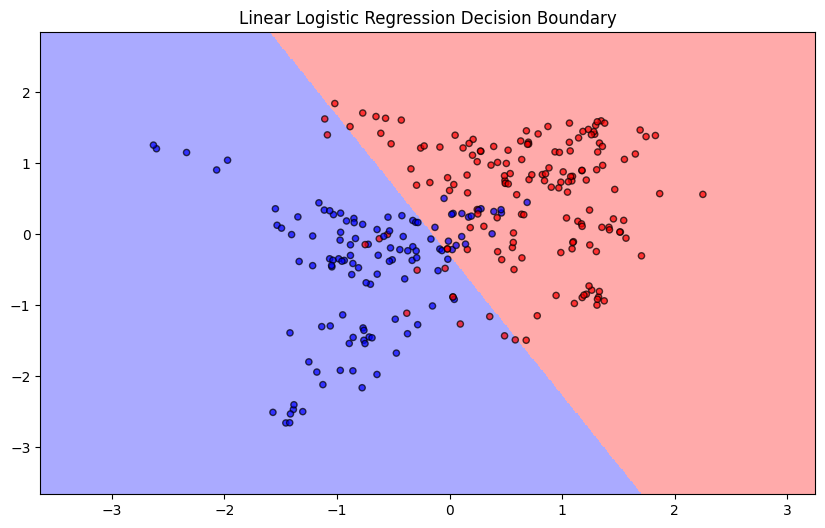

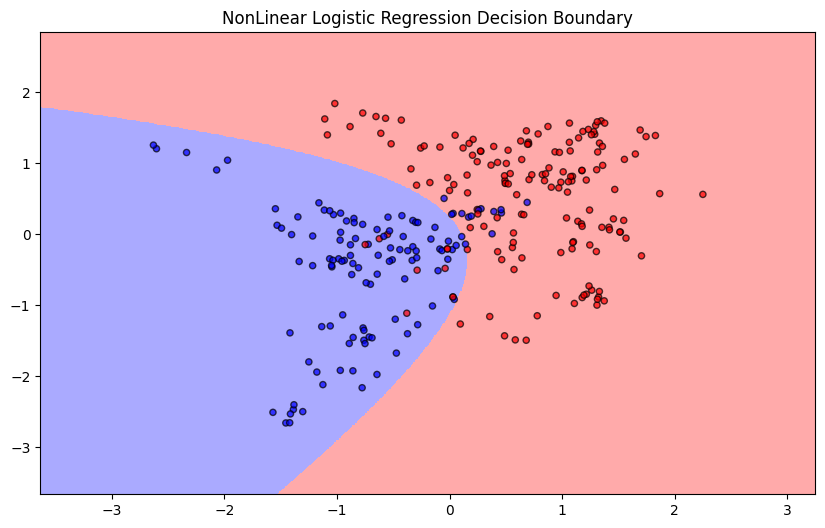

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm
from DecisionBoundary import plotDecisionBoundary

data = np.genfromtxt("datasets/banknote_authentication.csv", delimiter=",")
X = data[:, :2]
y = data[:, 2]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

np.random.seed(865)
indices = np.random.permutation(len(X_norm))

X_train = X_norm[indices[: int(len(X_norm) * 0.8)]]
y_train = y[indices[: int(len(y) * 0.8)]]
X_test = X_norm[indices[int(len(X_norm) * 0.8) :]]
y_test = y[indices[int(len(y) * 0.8) :]]

best_lr_lin = 0.07
best_lr_nonlin = 0.07
best_iters_lin = 1000
best_iters_nonlin = 2000

degree = 2

linear_model = mlm.LogisticRegression(learning_rate=best_lr_lin, num_iterations=best_iters_lin)
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
linear_accuracy = np.mean(linear_predictions == y_test)

nonlinear_model = mlm.NonLinearLogisticRegression(degree=degree, learning_rate=best_lr_nonlin, num_iterations=best_iters_nonlin)
nonlinear_model.fit(X_train, y_train)
nonlinear_predictions = nonlinear_model.predict(X_test)
nonlinear_accuracy = np.mean(nonlinear_predictions == y_test)

print(f"Linear LogisticRegression - Accuracy: {linear_accuracy:.4f}")
print(f"NonLinear LogisticRegression - Accuracy: {nonlinear_accuracy:.4f}")

plotDecisionBoundary(X_test[:, 0], X_test[:, 1], y_test, linear_model)
plt.title("Linear Logistic Regression Decision Boundary")
plt.show()

plotDecisionBoundary(X_test[:, 0], X_test[:, 1], y_test, nonlinear_model)
plt.title("NonLinear Logistic Regression Decision Boundary")
plt.show()



## Lecture 4 - Model Selection and Regularization

### Guidelines for model implementation (Mandatory)

* Implement a class **ROCAnalysis** that calculates the metrics: TP-rate, FP-rate, precision, recall (i.e., same as tp-rate) and f-score.
* Implement a class **ForwardSelection** that implements the feature forward selection algorithm seen in class. This process must use 80% (i.e., fitting the data) of the data for training the models and 20% (i.e., predicting in unseen data) for testing. This method should optimize your problem regarding the TP-rate metric. You must use your implementation of the **ROCAnalysis** class.

For this exercise, you will use the *heart_disease_cleveland.csv* dataset. The dataset contains 13 numerical features, and the last feature is the target variable, which we have to predict. The value of 1 means the patient is suffering from heart disease, and 0 means the patient is normal.

### Using your implementations of ROCAnalysis and ForwardSelection (All Mandatory)

1. **(Mandatory)** Start by normalizing the data and separating a validation set with 20\% of the data randomly selected. The remaining 80\% will be called the sub-dataset.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm
import ROCAnalysis as roc
import ForwardSelection as fs

data = np.genfromtxt("datasets/heart_disease_cleveland.csv", delimiter=",", dtype=None, encoding='utf-8')
X = np.array(data[1:, :-1], dtype=float)
y = np.array(data[1:, -1], dtype=float)

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

fs_temp = fs.ForwardSelection(X_norm, y, None)
X_train, X_test, y_train, y_test = fs_temp.create_split(X_norm, y)

2. **(Mandatory)** Use your implementation of forward selection to estimate a reasonable classification model. You must use your implementation of Logistic Regression in this assignment. The decision to make a reasonable number of iterations and learning rate is up to you but must be justified. Optimize the model selection to produce the best f-score. You must use the sub-dataset in your forward selection process. Report the features selected by this process and discuss your results. 

---

The algorithm selected seven features in this order:

1. thalach
2. restecg
3. sex
4. cp
5. fbs
6. ca
7. slope

This combination of features optimized the F-score by balancing the model's precision and recall, creating an efficient prediction model without including unnecessary variables.

In [18]:
model = mlm.LogisticRegression()
selector = fs.ForwardSelection(X_train, y_train, model)
selector.fit()

feature_names = np.array(data[0, :-1], dtype=str)

selected_feature_names = [feature_names[i] for i in selector.selected_features]

print("\nSelected feature names:")
for i, feature in enumerate(selected_feature_names):
    print(f"{i+1}. {feature}")


Selected feature names:
1. thalach
2. restecg
3. sex
4. cp
5. fbs
6. ca
7. slope


3. **(Mandatory)** Report the performance of the best model in the validation set regarding all statistics available in your ROCAnalysis class. 
Was the process successful when compared to using all features?  
Discuss your results regarding these metrics and what you can conclude from this experiment.

---

Based on the performance metrics:

Model with Selected Features:
- TP Rate (Recall): 0.9259
- FP Rate: 0.1471
- Precision: 0.8333
- F-score: 0.8772

Model with All Features:
- TP Rate (Recall): 0.8889
- FP Rate: 0.0882
- Precision: 0.8889
- F-score: 0.8889

The feature selection process was partially successful. The selected features model achieves higher recall (0.9259 vs 0.8889), identifying more positive cases, but at the cost of a higher false positive rate (0.1471 vs 0.0882).

The all-features model shows better precision (0.8889 vs 0.8333) and a marginally higher F-score (0.8889 vs 0.8772). This indicates that the complete feature set maintains a slightly better balance between precision and recall.

The minimal difference in F-scores (just 0.0117) suggests that the selected features capture most of the predictive power of the full dataset. This demonstrates that feature selection successfully identified the most important variables while only sacrificing a small amount of performance, potentially improving model interpretability and reducing computational requirements.

In [19]:
y_pred_selected = selector.predict(X_test)

all_features_model = mlm.LogisticRegression()
all_features_model.fit(X_train, y_train)

y_pred_all = all_features_model.predict(X_test)

selected_roc = roc.ROCAnalysis(y_pred_selected, y_test)
all_features_roc = roc.ROCAnalysis(y_pred_all, y_test)

print("Model with Selected Features:")
print(f"TP Rate (Recall): {selected_roc.tp_rate():.4f}")
print(f"FP Rate: {selected_roc.fp_rate():.4f}")
print(f"Precision: {selected_roc.precision():.4f}")
print(f"F-score: {selected_roc.f_score():.4f}")

print("\nModel with All Features:")
print(f"TP Rate (Recall): {all_features_roc.tp_rate():.4f}")
print(f"FP Rate: {all_features_roc.fp_rate():.4f}")
print(f"Precision: {all_features_roc.precision():.4f}")
print(f"F-score: {all_features_roc.f_score():.4f}") 

Model with Selected Features:
TP Rate (Recall): 0.9259
FP Rate: 0.1471
Precision: 0.8333
F-score: 0.8772

Model with All Features:
TP Rate (Recall): 0.8889
FP Rate: 0.0882
Precision: 0.8889
F-score: 0.8889


## Lecture 5 - Neural Networks

In this exercise you are allowed to use the scikit-learn package.

**(Mandatory)** First, load the digits dataset using *sklearn.datasets.load_digits*. Split the data into training and test sets (e.g., 80/20 split using train_test_split). Finally, plot 16 random images from the dataset in a 4×4 grid using matplotlib, with their labels displayed.

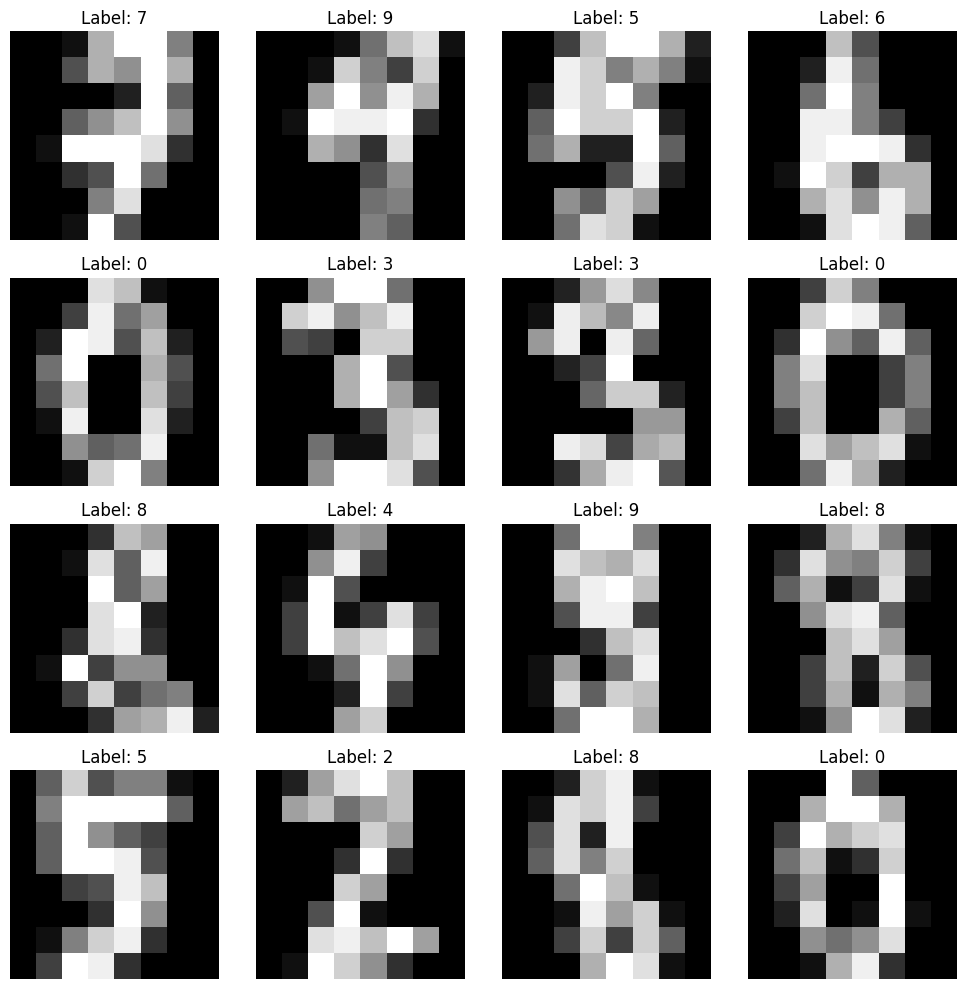

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, log_loss

np.random.seed(4632)

digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4632)

plt.figure(figsize=(10, 10))

random_indices = np.random.randint(0, len(images), 16)

for i, idx in enumerate(random_indices):
    plt.subplot(4, 4, i + 1)
    plt.imshow(images[idx], cmap='gray')
    plt.title(f"Label: {y[idx]}")
    plt.axis('off')
    
plt.tight_layout()
plt.show()

**(Mandatory)** Use MLPClassifier from *sklearn.neural_network*. 

Train an MLP on the training set and evaluate on the test set.

Then, use cross-validation (e.g., with GridSearchCV or cross_val_score) to explore:

* Number and size of hidden layers

* Activation functions: relu, tanh, logistic

* Learning rate strategies: constant, adaptive

* L2 regularization (alpha)

* Solvers: adam, sgd


Compare different configurations and choose the best-performing model.

Report cross-validation scores and final test accuracy.

---

The first MLP classifier got 96.94% accuracy on the test set. To improve it, I ran a grid search over different hyperparameters using 3-fold cross-validation.

Here’s what I tested:

- Hidden layers: Single layers (50, 100) and two-layer setups (50-50, 100-50)
- Activation: relu, tanh, logistic
- Learning rate: constant, adaptive
- Alpha: 0.0001, 0.001, 0.01
- Solvers: adam, sgd


The best setup was:
- A single hidden layer with 100 neurons
- Logistic (sigmoid) activation function
- Constant learning rate
- Low regularization (alpha=0.0001)
- Adam optimizer

Performance:
- Cross-validation score: 97.36%
- Test accuracy: 96.67%

The test accuracy was slightly lower than the cross-validation score, which shows the model generalizes well without overfitting. 

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mlp = MLPClassifier(max_iter=1000, random_state=695)
mlp.fit(X_train_scaled, y_train)
y_pred = mlp.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'activation': ['relu', 'tanh', 'logistic'],
    'learning_rate': ['constant', 'adaptive'],
    'alpha': [0.0001, 0.001, 0.01],
    'solver': ['adam', 'sgd']
}

grid_search = GridSearchCV(MLPClassifier(max_iter=5000, random_state=4632), param_grid, cv = 3, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.4f}")

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
accuracy_best = accuracy_score(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.4f}")


Accuracy: 0.9694
Best Parameters: {'activation': 'logistic', 'alpha': 0.0001, 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'solver': 'adam'}
Best Cross-Validation Score: 0.9736
Best Model Accuracy: 0.9667


**(Non-mandatory)**  Plot the confusion matrix for your best model on the test set.

Which digits are often confused?

---

Based on the confusion matrix, the model performs very well overall with most digits correctly classified. The few cases of misclassification show certain patterns:

- Digit 8 is confused with digit 1 (2 instances), likely due to the vertical line in the numeral 8 being detected as a 1 and with digit 0 (1 instance), likely due to the structural elements
- Multiple digits (4, 5, 6) are occasionally confused with digit 8, propabably because 8 shares structural elements with these digits
- Digits 4, 5, and 7 are sometimes confused with digit 9, these digits share curved or angled elements
- Digit 9 is once confused with digit 3 - both have curved segments

The most frequent confusion involves digit 8, which is misclassified as digits 0 and 1, possibly due to its complex structure containing elements of many other digits.

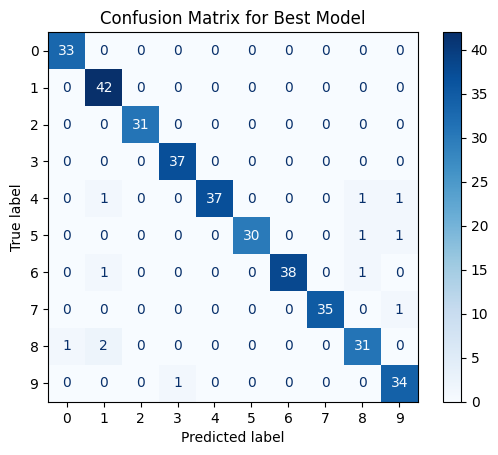

In [22]:
cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for Best Model")
plt.show()

**(Non-Mandatory)** Plot at least 10 misclassified images with predicted and true labels.

Try to identify patterns in the errors (e.g., similar-looking digits).

Are the misclassifications understandable for humans? Why or why not?

---

Looking at the misclassified images, here are some patterns I noticed:

1. Digit 8 is frequently misclassified as 1 or 0
   - When 8's vertical line is prominent but loops are faint, it resembles a 1
   - When 8's middle connection is weak, it can look like a 0

2. Digits with loops (4, 5, 6, 8, 9) are often confused with each other
   - The 5 predicted as 8 or 9 shows how similar their bottom loops can appear
   - The 4 predicted as 8 or 9 demonstrates similar ambiguity in the lower region

3. Vertical strokes create confusion
   - Multiple digits (6, 8) are misclassified as 1 when vertical elements dominate
   - The 9 predicted as 3 shows how curved elements can be misinterpreted

These mistakes make sense from a human perspective. The low resolution (about 8x8 pixels) makes it hard to see small details. Even humans might struggle with some of these, like 8s being predicted as 1s because of their unclear features. A 7 being predicted as a 9 shows how a small curve at the bottom can change how it’s interpreted.

These errors show how hard it is to tell apart complex shapes when the resolution is so low.

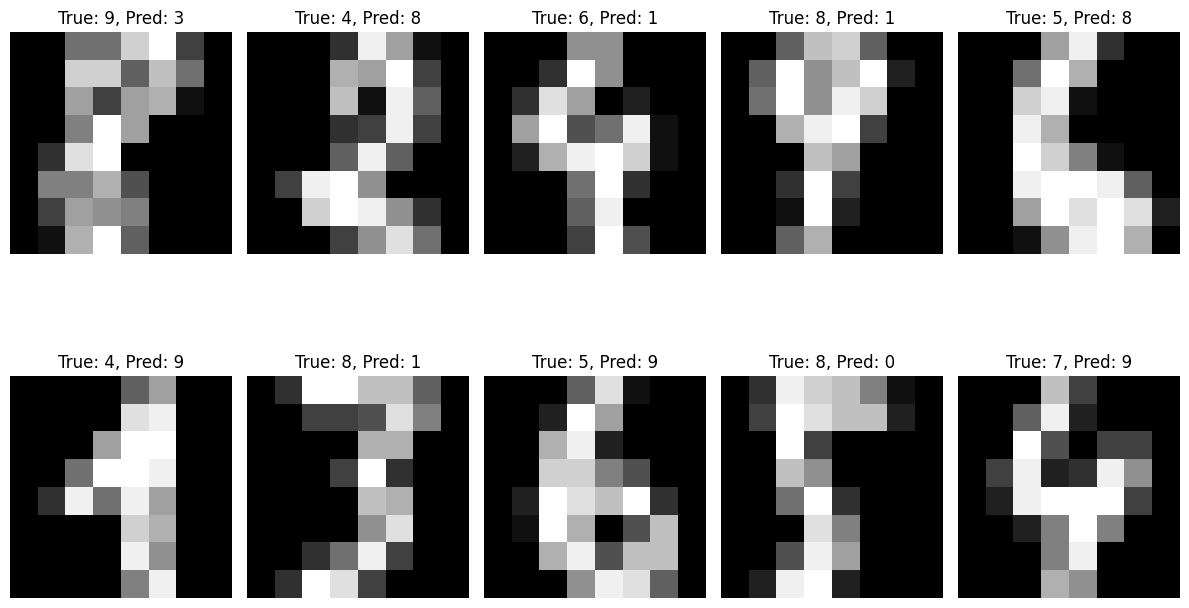

In [23]:
misclassified_indices = np.where(y_test != y_pred_best)[0]

selected_indices = misclassified_indices[:10]

plt.figure(figsize=(12, 8))
for i, idx in enumerate(selected_indices):
    plt.subplot(2, 5, i + 1) 
    plt.imshow(images[idx], cmap='gray')  
    plt.title(f"True: {y_test[idx]}, Pred: {y_pred_best[idx]}")
    plt.axis('off') 
    
plt.tight_layout()
plt.show()

**(Non-Mandatory)** 

Plot training/validation accuracy or loss over epochs if you're capturing it (using verbose=True or tracking manually).

How quickly does your model reach a stable accuracy or loss?

Is the training accuracy much higher than the validation accuracy?

Does the loss decrease on training but increase on validation?

---

The model learns quickly, reaching 90% accuracy within the first 25 epochs and stabilizing around epochs.

The training accuracy gets close to 100%, while the validation accuracy stops improving around 97%. This small 3% difference shows a bit of overfitting, but it’s not a big problem for this task.

Both training and validation loss decrease rapidly at first, then more gradually. It’s good that the validation loss stays steady instead of going up, which would mean overfitting is becoming an issue.

The model performs well pretty early (by around epoch 50), and after that, the improvements are smaller. The validation accuracy staying consistent and the validation loss staying stable show that the model generalizes well. However, the small gap growing between training and validation metrics suggests the model is starting to memorize the training data instead of learning patterns that work for new data.


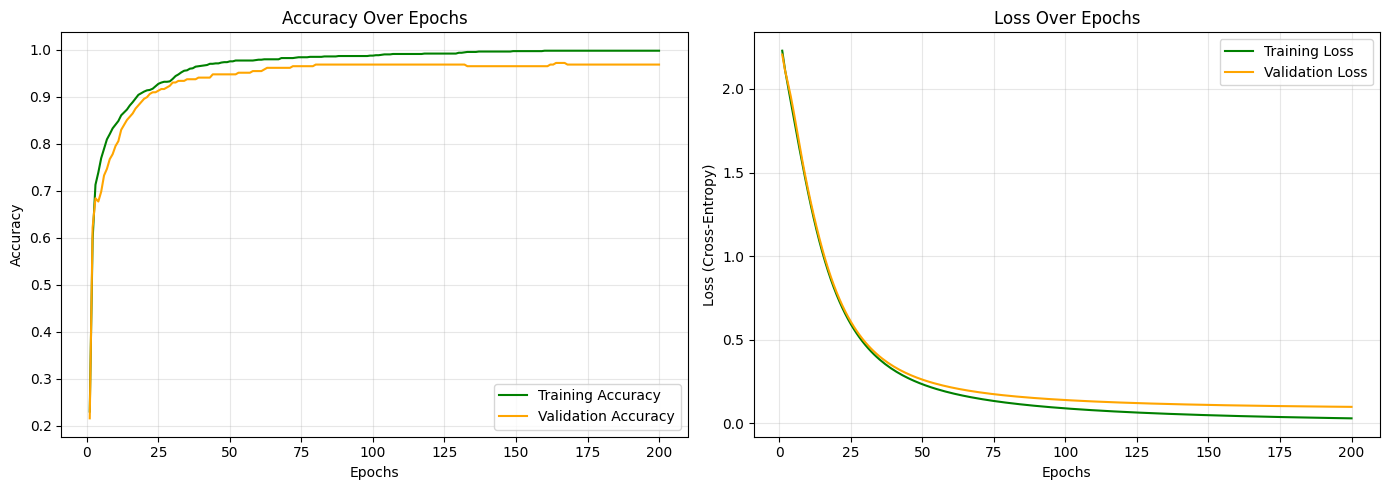

In [24]:
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=65
)

mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='logistic',
    solver='adam',
    alpha=0.0001,
    learning_rate='constant',
    max_iter=1, 
    warm_start=True,
    random_state=65
)


num_epochs = 200
epoch_list = []
training_losses = []
training_accuracies = []
validation_losses = []
validation_accuracies = []

def one_hot_encode(labels, num_classes=10):
    encoded = np.eye(num_classes)[labels]
    return encoded

y_train_encoded = one_hot_encode(y_train_split)
y_val_encoded = one_hot_encode(y_val)

unique_classes = np.unique(y_train_split)

for epoch in range(num_epochs):
    mlp_model.partial_fit(X_train_split, y_train_split, classes=unique_classes)
    
    train_predictions = mlp_model.predict(X_train_split)
    val_predictions = mlp_model.predict(X_val)
    
    train_probabilities = mlp_model.predict_proba(X_train_split)
    val_probabilities = mlp_model.predict_proba(X_val)
    
    epoch_list.append(epoch + 1)
    training_losses.append(log_loss(y_train_encoded, train_probabilities))
    training_accuracies.append(accuracy_score(y_train_split, train_predictions))
    validation_losses.append(log_loss(y_val_encoded, val_probabilities))
    validation_accuracies.append(accuracy_score(y_val, val_predictions))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epoch_list, training_accuracies, label='Training Accuracy', color='green')
axes[0].plot(epoch_list, validation_accuracies, label='Validation Accuracy', color='orange')
axes[0].set_title('Accuracy Over Epochs')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epoch_list, training_losses, label='Training Loss', color='green')
axes[1].plot(epoch_list, validation_losses, label='Validation Loss', color='orange')
axes[1].set_title('Loss Over Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss (Cross-Entropy)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()